<a href="https://colab.research.google.com/github/OJB-Quantum/Qiskit-Metal-to-Litho/blob/main/Python%20Code_Qiskit%20Metal_Designs/Wallraff_17Q_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 17-Qubit Surface-Code Chip (Wallraff group, ETH Zurich)

> 💡 **Running in Colab or Binder?** Uncomment the install cell below. The notebook runs headless there — no Qt, no Ansys, about a minute end to end. On a desktop with the GUI installed, it also opens the chip in `MetalGUI` and updates it after every stage.

In 2022, the Quantum Device Lab at ETH Zurich ran repeated rounds of quantum error correction on a distance-three surface code — seventeen superconducting qubits on one die ([Krinner *et al.*, *Nature* 2022](https://doi.org/10.1038/s41586-022-04566-8)). In this notebook you build that chip in Quantum Metal, from the bare die to the last feedline, and check the design after every step.

**What you'll learn**

- how a surface-code processor is laid out: data and auxiliary qubits, couplers, control lines, readout with Purcell filters, multiplexed feedlines;
- how to draw a line that follows a known path with `PolylineCPW`, and connect to it partway along with *taps*;
- how to carry one line over another with an `Airbridge`;
- how to run Metal's design-rule check after every stage, including the shape rules that catch hairpins, self-crossings and unterminated line ends;
- how to export the chip to GDS, and how to change it and see the check respond.

| | |
|---|---|
| Qubits | 17 transmons: 9 data, 8 auxiliary |
| Die | 14.4 mm square, 48 wire-bond launchpads |
| Readout | 17 quarter-wave resonators, 17 Purcell filters, 4 feedlines |
| Components | 348 |
| Run time | about 1 minute |

## The device, and thanks

The chip is the design of the [Quantum Device Lab](https://qudev.phys.ethz.ch/) of Andreas Wallraff at ETH Zurich, used in S. Krinner, N. Lacroix, A. Remm *et al.* [1] and, in a device of the same design, for lattice surgery by I. Besedin, M. Kerschbaum *et al.* [2]. It builds on the group's earlier seven-qubit surface-code work [3] and on their multiplexed readout with individual Purcell filters [4, 5].

**Thank you** to Andreas Wallraff and the Quantum Device Lab for sharing this design openly — in the [lecture slides](https://polybox.ethz.ch/index.php/s/CnsHoKWW6xQKZAA) and in the talks [here](https://www.youtube.com/watch?v=floIDDd6ZXA), [here](https://www.youtube.com/watch?v=CgNz4wsD0oI), and at the Quantum Device Workshop ([lecture](https://www.youtube.com/watch?v=0r1YPMcmuFU)). Every position and path in this notebook was measured from the micrographs in those slides.

> ⚠️ **A mockup, not a mask.** This is a reconstruction for learning, and it is not perfect. Dimensions the images cannot resolve are chosen; each junction is a single junction standing in for the device's SQUID; and line crossings are drawn as airbridges, where the device uses integrated crossovers. The full list is under *Known issues* at the end.

> 🤖 **Rebuilt by AI agents, on top of Quantum Metal**
>
> The layout was reconstructed by AI coding agents working through Metal's Python API, with a person reviewing every stage: measuring the die from the slide images, writing the builder, and fixing what the design-rule check found.
>
> Reproducing a published device is a test, not the goal: the answer is known, so every mistake shows. The goal is designing *new* chips with AI — starting from a specification (qubits, connectivity, frequencies) and laying out, checking and simulating in Metal. That workflow is written up as the [`chip-design`](https://github.com/qiskit-community/qiskit-metal/blob/main/.claude/skills/chip-design/SKILL.md) agent skill. This notebook is a small, complete run of its core loop: build in stages, check every stage, change something, check again.

### Setup

**GUI or headless.** `qm.gui(design)` opens the desktop `MetalGUI` when Qt and a display are available, and falls back to an inline headless viewer otherwise (Colab, Binder, a server). Set `HEADLESS` to choose yourself: `True` for inline figures, `False` to require the desktop GUI. In the desktop GUI each stage is drawn in the GUI window and a screenshot of it lands in the notebook; headless, Metal draws an inline figure instead. The outputs saved in this notebook, and shown in the docs, come from a headless run.

The builder (`wallraff_17q.py`) and the measured geometry (`geometry.json`) live in `resources/wallraff_17q/` beside this notebook. Colab opens a notebook on its own, so the cell fetches them if they are missing.

In [19]:
# In Colab / Binder, uncomment to install Quantum Metal (lite, no Qt).
# Locally you should already have it via `pip install quantum-metal` or
# `pip install 'quantum-metal[gui]'` for the desktop GUI.
!uv pip install -q quantum-metal

In [20]:
"""This script builds the 17-qubit chip with native Quantum Metal geometry."""

# --- Control Knobs ---
CHIP_SIZE_X = "14.4mm"
CHIP_SIZE_Y = "14.4mm"
CHEESE_KEEPOUT = "25um"
GROUND_STRAP_PITCH = "500um"
OUTPUT_FILENAME = "Wallraff_17Q.gds"

# --- Imports ---
import hashlib
import logging
import sys
import urllib.request
import warnings
from collections import Counter
from pathlib import Path
from types import SimpleNamespace

import gdstk
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import FileLink, display
from matplotlib.collections import PolyCollection

import qiskit_metal as qm
from qiskit_metal import Dict, designs, draw
from qiskit_metal.qlibrary.core import QComponent
from qiskit_metal.qlibrary.qubits.SQUID_loop import SQUID_LOOP
from qiskit_metal.qlibrary.tlines.airbridge import Airbridge, route_airbridges
from qiskit_metal.renderers.renderer_gds.gds_renderer import QGDSRenderer
from qiskit_metal.validation import DEFAULT_RULES, SHAPE_RULES, Waiver, validate
from qiskit_metal.validation.rules import GroundContinuityRule

plt.rcParams["figure.dpi"] = 250

# --- Published Example Resources ---
commit = "6d58dd77e3ac053c746e8cf14aa708348c6e8003"
RES = Path("resources") / f"wallraff_17q_{commit[:7]}"
RES.mkdir(parents=True, exist_ok=True)
base = (
    f"https://raw.githubusercontent.com/qiskit-community/qiskit-metal/{commit}/"
    "docs/circuit-examples/F.Small-quantum-chips/resources/wallraff_17q/"
)
resource_hashes = {
    "wallraff_17q.py": "8e68f0727945bae0e08bb52c1182ccae12a76d18bb9ab6e4128dc14eb20f605b",
    "chip_inspect.py": "8e7ecb2be5460cee7ae15b575f4d7563b1ed464a01ad80d75a33269f7319356f",
    "geometry.json": "4977d5b47396e4a218c3023bdf849910ea409d177902051da6ca64e1374fb6dd",
}
for filename, expected_hash in resource_hashes.items():
    target = RES / filename
    if (
        not target.exists()
        or hashlib.sha256(target.read_bytes()).hexdigest() != expected_hash
    ):
        urllib.request.urlretrieve(base + filename, target)
    assert hashlib.sha256(target.read_bytes()).hexdigest() == expected_hash, filename
sys.path.insert(0, str(RES.resolve()))

import wallraff_17q as chip
from chip_inspect import inspect_sites

# --- Layout Specifications ---
chip.READOUT_PAD = 42
chip.COUPLER_PAD = {0: 325, 90: 112, 180: 180, 270: 252}
parameter_table = pd.DataFrame(
    [
        ("Lattice pitch x / y", f"{chip.AX:.4f} / {chip.AY:.4f} mm", "Image-derived"),
        ("CPW center / gap", "8.5 / 5.5 um", "Nominal; image-informed"),
        ("Capacitor gaps", "10 um", "Nominal; image-informed"),
        (
            "Pads relative to SQUID axis",
            "42, 112, 180, 252, 325 degrees",
            "Image-derived; mirrored per site",
        ),
        ("Nb thickness", "150 nm", "Published, Appendix A"),
        ("SQUID loop gap / branch width", "10 um / 200 nm", "Nominal"),
        ("JJ overlaps", "200 x 200 / 200 x 400 nm", "Nominal; area ratio 1:2"),
        ("Signal crossover span / width", "110 / 8.5 um", "Nominal"),
        ("Ground strap span / width", "50 / 8.5 um", "Nominal"),
        (
            "Al-Ti-Al airbridge process",
            "Reflow scaffold, contacts, released span",
            "Published architecture; nominal mask sizes",
        ),
        ("Cheese hole edge setback", "100 um minimum", "Design specification"),
    ],
    columns=["Parameter", "Value", "Basis"],
)
display(parameter_table)
layer_table = pd.DataFrame(
    [
        (1, "Nb", "Base ground, CPW, islands, launchpads"),
        (
            2,
            "Sacrificial resist",
            "Reflow scaffold pattern; removed after bridge metal",
        ),
        (3, "Al-Ti-Al", "Elevated signal crossings and ground straps"),
        (4, "Bridge contacts", "Landing/contact windows"),
        (5, "Al", "Lower SQUID electrode"),
        (6, "Al", "Upper SQUID electrode"),
        (
            7,
            "JJ overlap reference",
            "Derived overlap areas; the Al oxide barrier forms during evaporation",
        ),
        (8, "Al", "Bandage contacts between SQUID electrodes and Nb"),
    ],
    columns=["GDS layer", "Material or mask", "Role"],
)
display(layer_table)

,Parameter,Value,Basis
0,Lattice pitch x / y,1.6092 / 1.7539 mm,Image-derived
1,CPW center / gap,8.5 / 5.5 um,Nominal; image-informed
2,Capacitor gaps,10 um,Nominal; image-informed
3,Pads relative to SQUID axis,"42, 112, 180, 252, 325 degrees",Image-derived; mirrored per site
4,Nb thickness,150 nm,"Published, Appendix A"
5,SQUID loop gap / branch width,10 um / 200 nm,Nominal
6,JJ overlaps,200 x 200 / 200 x 400 nm,Nominal; area ratio 1:2
7,Signal crossover span / width,110 / 8.5 um,Nominal
8,Ground strap span / width,50 / 8.5 um,Nominal
9,Al-Ti-Al airbridge process,"Reflow scaffold, contacts, released span",Published architecture; nominal mask sizes


,GDS layer,Material or mask,Role
0,1,Nb,"Base ground, CPW, islands, launchpads"
1,2,Sacrificial resist,Reflow scaffold pattern; removed after bridge ...
2,3,Al-Ti-Al,Elevated signal crossings and ground straps
3,4,Bridge contacts,Landing/contact windows
4,5,Al,Lower SQUID electrode
5,6,Al,Upper SQUID electrode
6,7,JJ overlap reference,Derived overlap areas; the Al oxide barrier fo...
7,8,Al,Bandage contacts between SQUID electrodes and Nb


## Build it one layer at a time

Six stages, each a function in the builder. After every stage we draw the design and run the design-rule check, so a finding points straight at the stage that caused it.

The check runs Metal's default rules -- which also look at the shape of each single line: a line crossing itself, a hairpin turn, a corner rounded less than was asked for, and a line that leaves the pin it connects to at an angle -- plus `SHAPE_RULES`, which adds one more: a line end left unconnected.

In [21]:
# --- Chip Footprint ---
design = designs.DesignPlanar(enable_renderers=False)
design.chips.main.size.size_x = CHIP_SIZE_X
design.chips.main.size.size_y = CHIP_SIZE_Y
chip_x = float(design.parse_value(CHIP_SIZE_X))
chip_y = float(design.parse_value(CHIP_SIZE_Y))
assert (
    chip_x >= 14.4 and chip_y >= 14.4
), "The traced 17-qubit layout needs a 14.4 mm footprint or larger."
RULES = [*DEFAULT_RULES, *SHAPE_RULES]

### 1. Die and launchpads

A 14.4 mm die with 48 wire-bond launchpads, twelve per edge on a 1 mm pitch. Six carry no line on the device; they are placed anyway, as they are on the die. Every launchpad is named after what it serves — `LP_flux_D5`, `LP_drive_D5`, `LP_feed_NE_N` or `LP_spare_...` — so you can find any line by name.

48 launchpads; outer metal edges 100 um inside the chip perimeter.


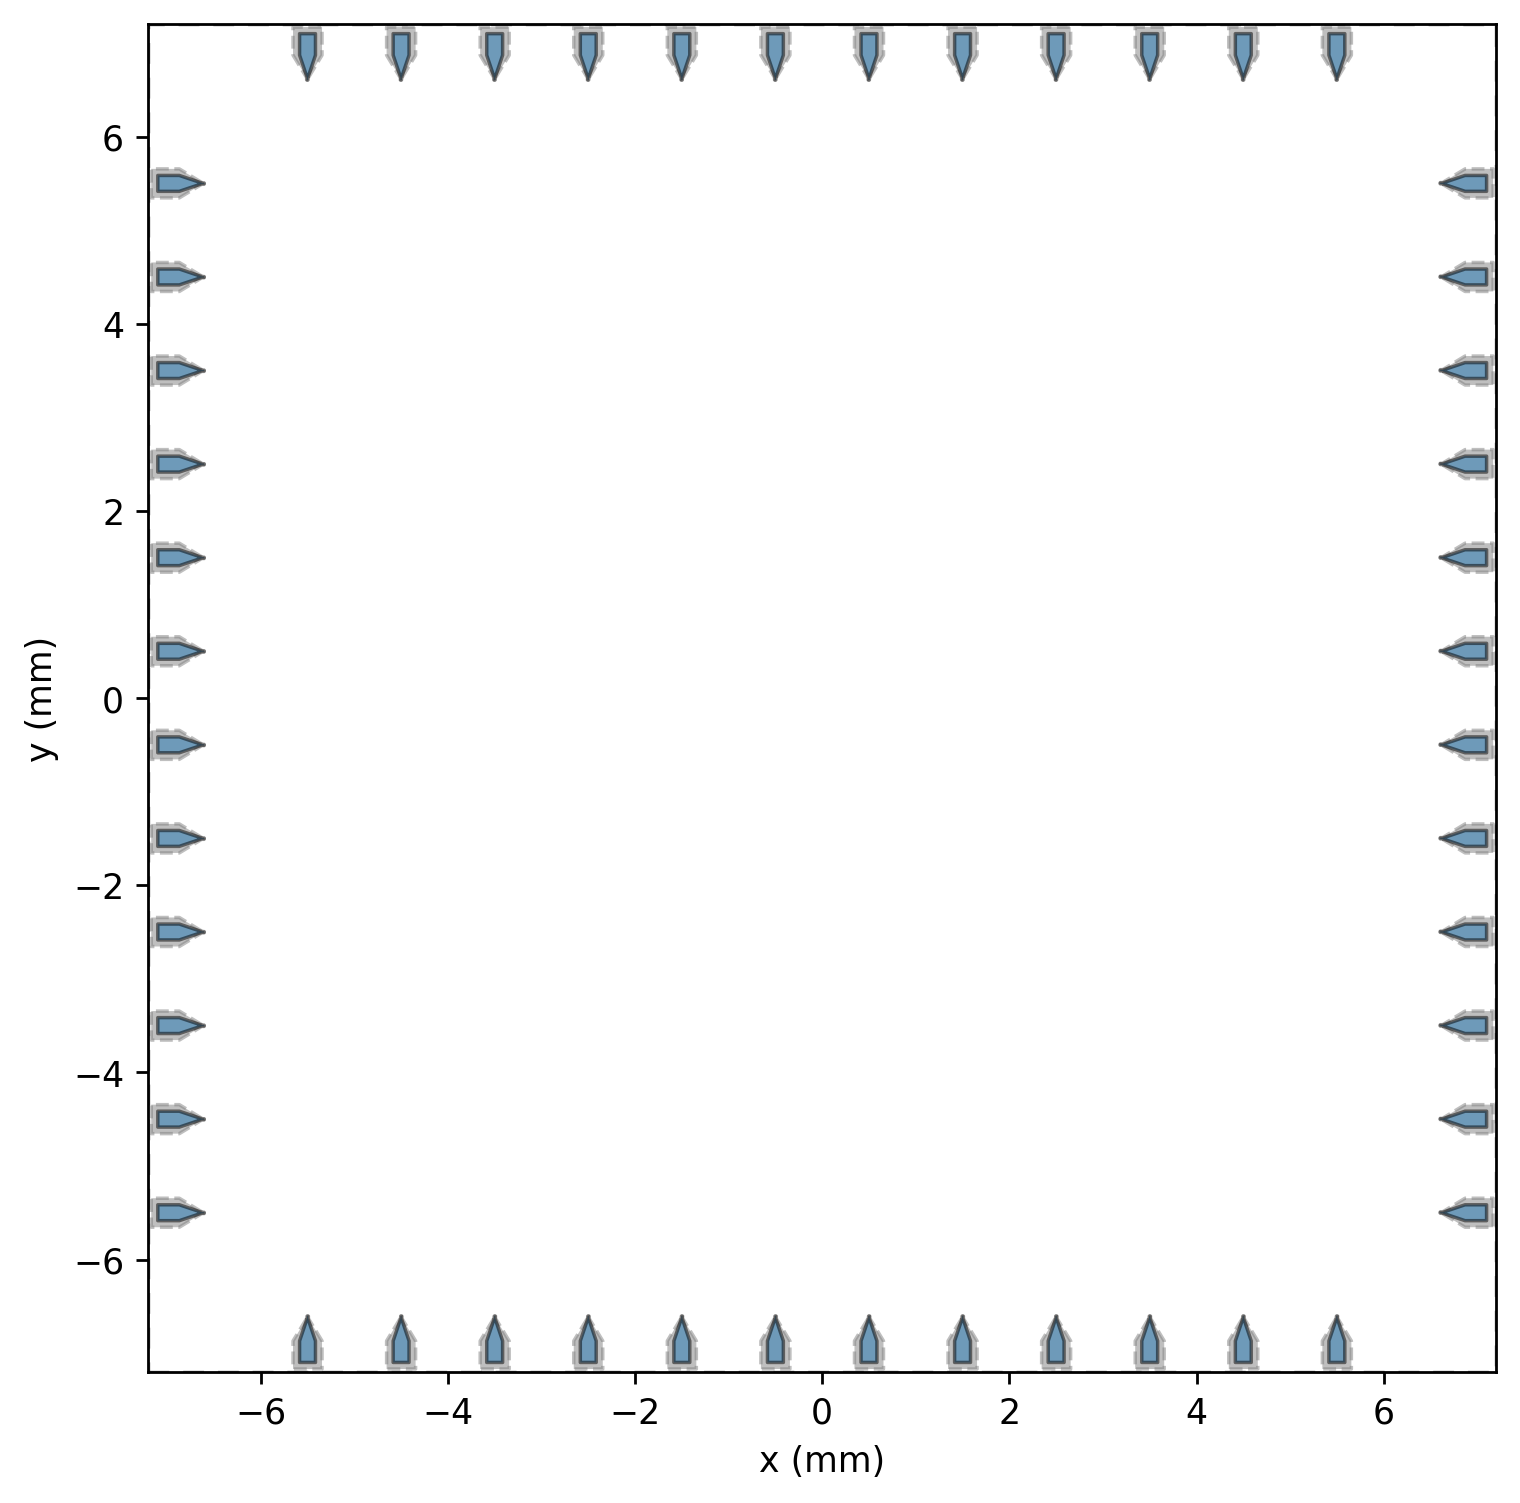

In [22]:
# --- Perimeter Launchpads ---
chip.stage_launchpads(design)
for pad in list(design.components.values()):
    angle = int(float(pad.p.orientation)) % 360
    if angle in (0, 180):
        pad.options.pos_x = f"{np.sign(float(pad.p.pos_x)) * (chip_x / 2 - .570)}mm"
    else:
        pad.options.pos_y = f"{np.sign(float(pad.p.pos_y)) * (chip_y / 2 - .570)}mm"
    pad.rebuild()
print("48 launchpads; outer metal edges 100 um inside the chip perimeter.")

fig = qm.view(design)
fig.set_size_inches(7, 7)
ax = fig.axes[0]
ax.set_xlim(-chip_x / 2, chip_x / 2)
ax.set_ylim(-chip_y / 2, chip_y / 2)
ax.set_aspect("equal")
ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
display(fig)
plt.close(fig)

### 2. Qubits

Seventeen star-shaped transmons (`StarQubit`), scaled to the measured island: an etched pocket about 0.32 mm across. Data qubits are named `D1`–`D9`; the auxiliary qubits that measure the stabilizers are `X1`–`X4` and `Z1`–`Z4`.

Each qubit is laid out like the device qubit in the close-up in the slides: five pads about 72° apart — the readout pad and four coupler pads — and the junction on the island arm between the readout pad and a coupler pad, facing the flux line. With the junction at 0°, the readout pad sits at 36° and the coupler pads at −36°, 108°, 180° and −108° (mirrored on qubits whose readout is on the other side). The device measures 42°, 112°, 180°, 252° and 325°. Qubits on the edge of the lattice keep their unused pads, as on the device.

> 👀 **Watch the angles.** `StarQubit` places each connector's pin 90° behind its `rotation_*` option, so the builder converts compass angles with `arm_rotation`; the junction's `rotation_jj` follows the same rule. Rather than trust that, the cell reads the *built* pins and junctions back and compares them with the layout.

In [23]:
# --- Star Transmons with Measured Pad Directions ---
chip.stage_qubits(design)
pad_records = []
for name in chip.QUBITS:
    q = design.components[name]
    expected = chip.pad_angles(name)
    actual = []
    for side, pin_name in chip.ARM_PIN.items():
        normal = np.asarray(q.pins[pin_name].normal)
        angle = float(np.degrees(np.arctan2(normal[1], normal[0])) % 360)
        assert abs((angle - expected["cpl"][side * 45] + 180) % 360 - 180) < 1e-6, name
        actual.append(round(angle, 3))
    pad_records.append((name, expected["jj"], expected["rdout"], *actual))
display(
    pd.DataFrame(
        pad_records,
        columns=[
            "Qubit",
            "SQUID axis (deg)",
            "Readout (deg)",
            "Coupler E (deg)",
            "Coupler N (deg)",
            "Coupler W (deg)",
            "Coupler S (deg)",
        ],
    )
)

,Qubit,SQUID axis (deg),Readout (deg),Coupler E (deg),Coupler N (deg),Coupler W (deg),Coupler S (deg)
0,Z1,180,138,0.0,68.0,215.0,288.0
1,D1,0,42,325.0,112.0,180.0,252.0
2,D4,180,138,0.0,68.0,215.0,288.0
3,X2,0,42,325.0,112.0,180.0,252.0
4,D2,0,42,325.0,112.0,180.0,252.0
5,X1,0,42,325.0,112.0,180.0,252.0
6,D7,180,138,0.0,68.0,215.0,288.0
7,Z2,180,138,0.0,68.0,215.0,288.0
8,D5,0,42,325.0,112.0,180.0,252.0
9,Z3,0,318,35.0,108.0,180.0,248.0


In [24]:
# --- Asymmetric Two-Junction SQUID Masks ---
for name in chip.QUBITS:
    q = design.components[name]
    axis, _ = chip.qubit_frame(name)
    angle = np.radians(axis)
    c = np.array([float(q.p.pos_x), float(q.p.pos_y)])
    unit = np.array([np.cos(angle), np.sin(angle)])
    # Keep the native island inside its 160 um disc; remove the single-JJ fork.
    table = design.qgeometry.tables["poly"]
    row = table.index[(table.component == q.id) & (table.name == "circle_inner")][0]
    table.at[row, "geometry"] = table.at[row, "geometry"].intersection(
        draw.Point(*c).buffer(0.160, quad_segs=16)
    )
    jt = design.qgeometry.tables["junction"]
    design.qgeometry.tables["junction"] = jt[jt.component != q.id].copy()
    tongue = draw.translate(
        draw.rotate(draw.rectangle(0.024, 0.014, 0.165, 0), axis, origin=(0, 0)), *c
    )
    q.add_qgeometry("poly", {"squid_contact": tongue}, layer=1)
    location = c + 0.172 * unit
    squid = SQUID_LOOP(
        design,
        f"SQUID_{name}",
        options=Dict(
            pos_x=f"{location[0]}mm",
            pos_y=f"{location[1]}mm",
            orientation=str(axis),
            layer="5",
            squid_gap="10um",
            segment_a_width="200nm",
            segment_b_width="200nm",
            segment_d_length="10um",
        ),
    )
    geo = squid.qgeometry_table("poly").geometry.union_all()
    local = draw.rotate(
        draw.translate(geo, -location[0], -location[1]), -axis, origin=(0, 0)
    )
    pieces = list(local.geoms)
    if pieces[0].centroid.x > pieces[1].centroid.x:
        pieces.reverse()
    lower, upper = pieces
    overlaps = []
    junctions = {}
    for i, (side, overlap) in enumerate(((-1, 0.0002), (1, 0.0004))):
        y = side * 0.0051
        upper = upper.union(
            draw.rectangle(
                0.0005 + overlap, 0.0002, 0.01275 + (0.0005 - overlap) / 2, y
            )
        )
        overlaps.append(draw.rectangle(overlap, 0.0002, 0.01275 - overlap / 2, y))
        junctions[f"JJ{i+1}"] = draw.LineString([(0.01275 - overlap, y), (0.01275, y)])
    lower = draw.translate(draw.rotate(lower, axis, origin=(0, 0)), *location)
    upper = draw.translate(draw.rotate(upper, axis, origin=(0, 0)), *location)
    masks = [
        draw.translate(draw.rotate(g, axis, origin=(0, 0)), *location) for g in overlaps
    ]
    jjs = {
        k: draw.translate(draw.rotate(g, axis, origin=(0, 0)), *location)
        for k, g in junctions.items()
    }
    pt = design.qgeometry.tables["poly"]
    design.qgeometry.tables["poly"] = pt[pt.component != squid.id].copy()
    squid.add_qgeometry("poly", {"lower_electrode": lower}, layer=5)
    squid.add_qgeometry("poly", {"upper_electrode": upper}, layer=6)
    squid.add_qgeometry(
        "poly", {f"overlap_{i+1}": g for i, g in enumerate(masks)}, layer=7
    )
    squid.add_qgeometry("junction", jjs, width=0.0002, layer=5)
    contacts = [draw.rectangle(0.004, 0.010), draw.rectangle(0.004, 0.010, 0.03225, 0)]
    contacts = [
        draw.translate(draw.rotate(g, axis, origin=(0, 0)), *location) for g in contacts
    ]
    squid.add_qgeometry("poly", {"bandages": draw.union(*contacts)}, layer=8)

assert len(design.qgeometry.tables["junction"]) == 34
print("17 SQUID loops; two junctions per loop; nominal areas 0.04 and 0.08 um².")

17 SQUID loops; two junctions per loop; nominal areas 0.04 and 0.08 um².


### 3. Lattice couplers

One coupler for every pair of nearest neighbors — this is the surface code's stabilizer graph. A data qubit has two, three or four neighbors, depending on whether it sits at a corner, an edge or the center.

The couplers follow measured paths, so they are drawn with `PolylineCPW`, which draws exactly the points it is given instead of routing. Each line leaves its qubit pin straight, along the pin's direction, for 40 µm, so the line meets the pad square-on and its end is flush with it; then it follows the trace. The coupler toward the neighbor on the flux-line side leaves its pad 36° off that neighbor's direction, to make room for the junction, and bends back toward it — the jog you can see on the device.

> ℹ️ From here on the check warns that the ground plane is split: the four couplers around each plaquette fence in an island of ground. On the device, airbridges tie those islands to the rest of the ground plane. The rule sees only metal on the ground layer, and says so.

24 nearest-neighbor lattice couplers.


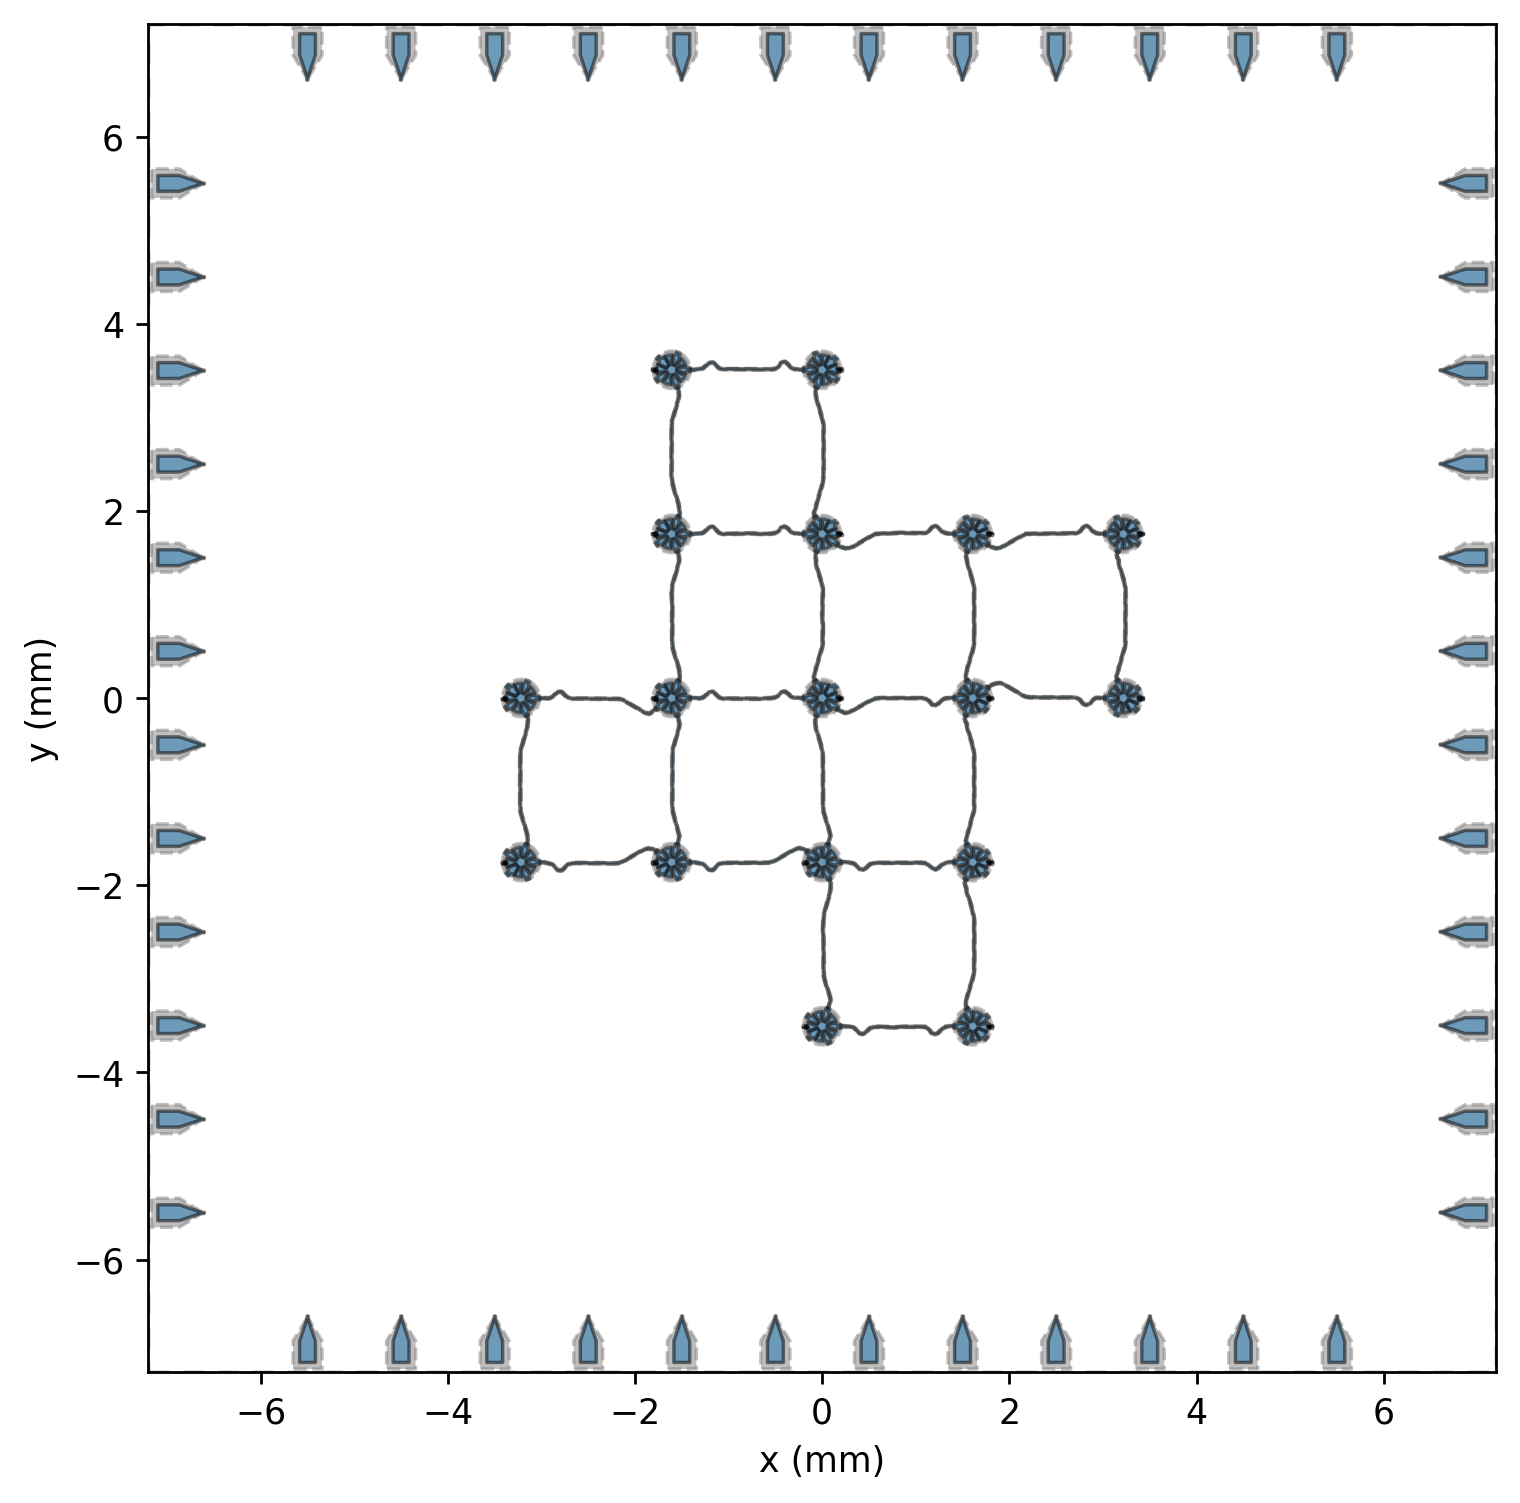

In [25]:
# --- Surface-Code Lattice Couplers ---
chip.stage_couplers(design)
assert len([name for name in design.components if name.startswith("CPL_")]) == 24
print("24 nearest-neighbor lattice couplers.")

fig = qm.view(design)
fig.set_size_inches(7, 7)
ax = fig.axes[0]
ax.set_xlim(-chip_x / 2, chip_x / 2)
ax.set_ylim(-chip_y / 2, chip_y / 2)
ax.set_aspect("equal")
ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
display(fig)
plt.close(fig)

### 4. Flux and drive lines

Each qubit gets a flux line from its own launchpad, ending in a short to ground beside the SQUID, and a drive line ending open beside the island.

The ends matter. The drive line couples capacitively, so its end must be open. A coplanar line whose end is simply left unconnected butts into the ground plane — on the wafer, that is a short. So every line end is terminated on purpose, and the `dangling-end` rule checks that none were forgotten.

Where a line crosses one drawn earlier, it is cut and carried over on an `Airbridge`. The bridge's pins `a` and `b` connect to the two cut ends, and the bridge metal sits on its own layer, so the crossing is not a short. (The device uses integrated crossovers here; the airbridge stands in for them.)

17 flux shorts; 17 microwave drive terminations.


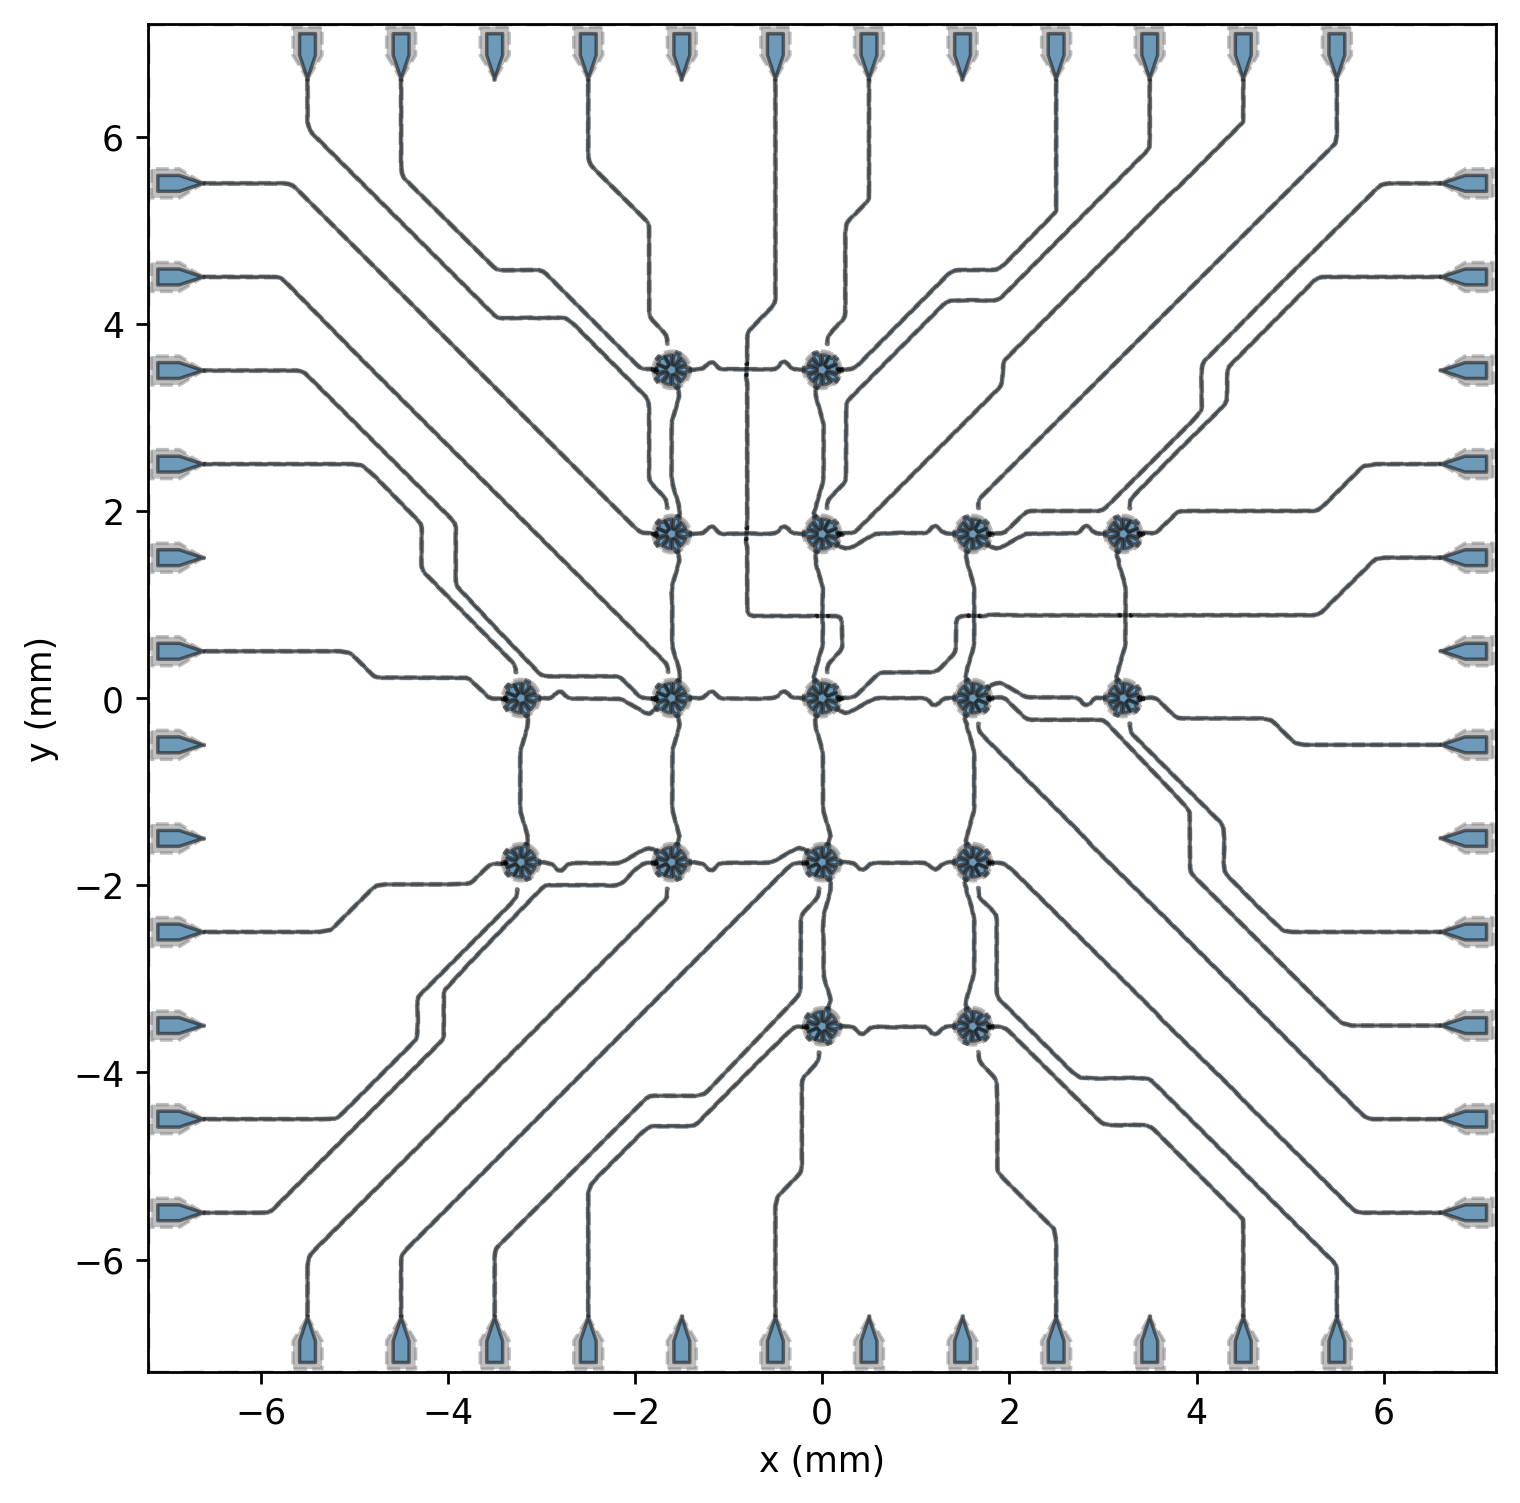

In [26]:
# --- Flux and Microwave Drive Lines ---
chip.stage_control_lines(design)
print("17 flux shorts; 17 microwave drive terminations.")

fig = qm.view(design)
fig.set_size_inches(7, 7)
ax = fig.axes[0]
ax.set_xlim(-chip_x / 2, chip_x / 2)
ax.set_ylim(-chip_y / 2, chip_y / 2)
ax.set_aspect("equal")
ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
display(fig)
plt.close(fig)

### 5. Readout resonators, Purcell filters and their couplers

Every qubit has its own readout resonator and its own Purcell filter, both quarter-wave lines [4]. The resonator is open at the qubit, where a triangular pad couples to the island, and shorted at its far end. The filter is shorted at one end and open at the other, where it couples to the feedline. The filter lets the readout signal out quickly while keeping the qubit from decaying through the same path.

Two small capacitors do the coupling:

- **Resonator–filter coupler**: a pad on each line, facing across a gap midway between them — `CapNInterdigital` with two fingers of zero length. It connects to *taps*: pins partway along each `PolylineCPW`, so each joint is a real, registered connection.
- **Filter–feedline coupler**: `CapFingerInFrame`, a frame electrode around a single finger. Its cross-section is the same on all 17; its length is set per qubit, and sets how strongly that filter couples to the feedline.

> ✅ **A sanity check on the tracing.** The traced resonator lengths track the readout frequencies reported in the paper (6.77–7.55 GHz): the shorter resonators belong to the higher-frequency auxiliary qubits.

17 readout resonators and 17 Purcell filters.


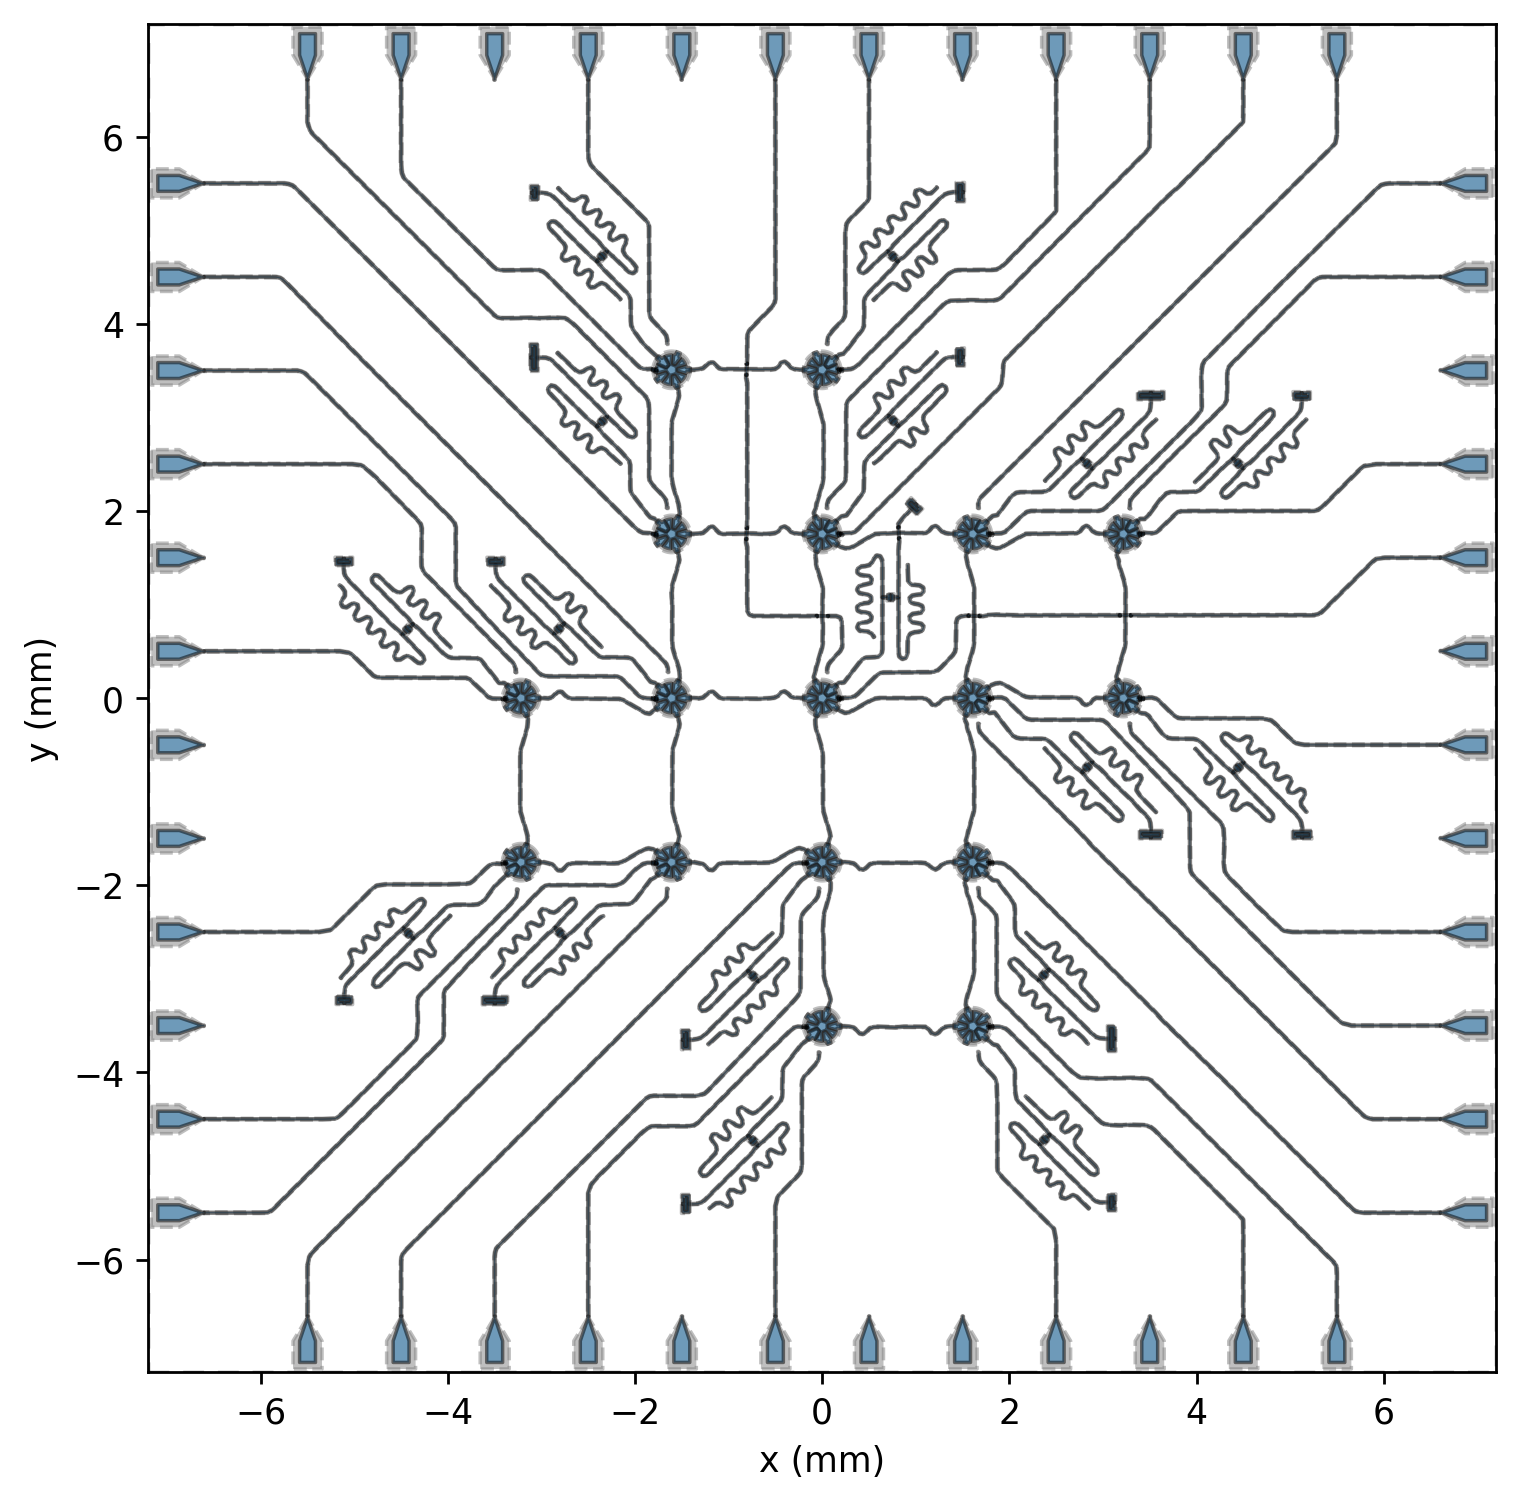

In [27]:
# --- Readout Resonators and Purcell Filters ---
chip.stage_readout(design)
print("17 readout resonators and 17 Purcell filters.")

fig = qm.view(design)
fig.set_size_inches(7, 7)
ax = fig.axes[0]
ax.set_xlim(-chip_x / 2, chip_x / 2)
ax.set_ylim(-chip_y / 2, chip_y / 2)
ax.set_aspect("equal")
ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
display(fig)
plt.close(fig)

### 6. Feedlines and input capacitors

Four feedlines, one per quadrant, each reading out four or five qubits. Each runs from a launchpad on one edge to a launchpad on the neighboring edge, starts with a series input capacitor (the same `CapFingerInFrame` cell), and taps off a short stub to the finger of every filter coupler in its group.

Four feedline groups with native in-line input capacitors.


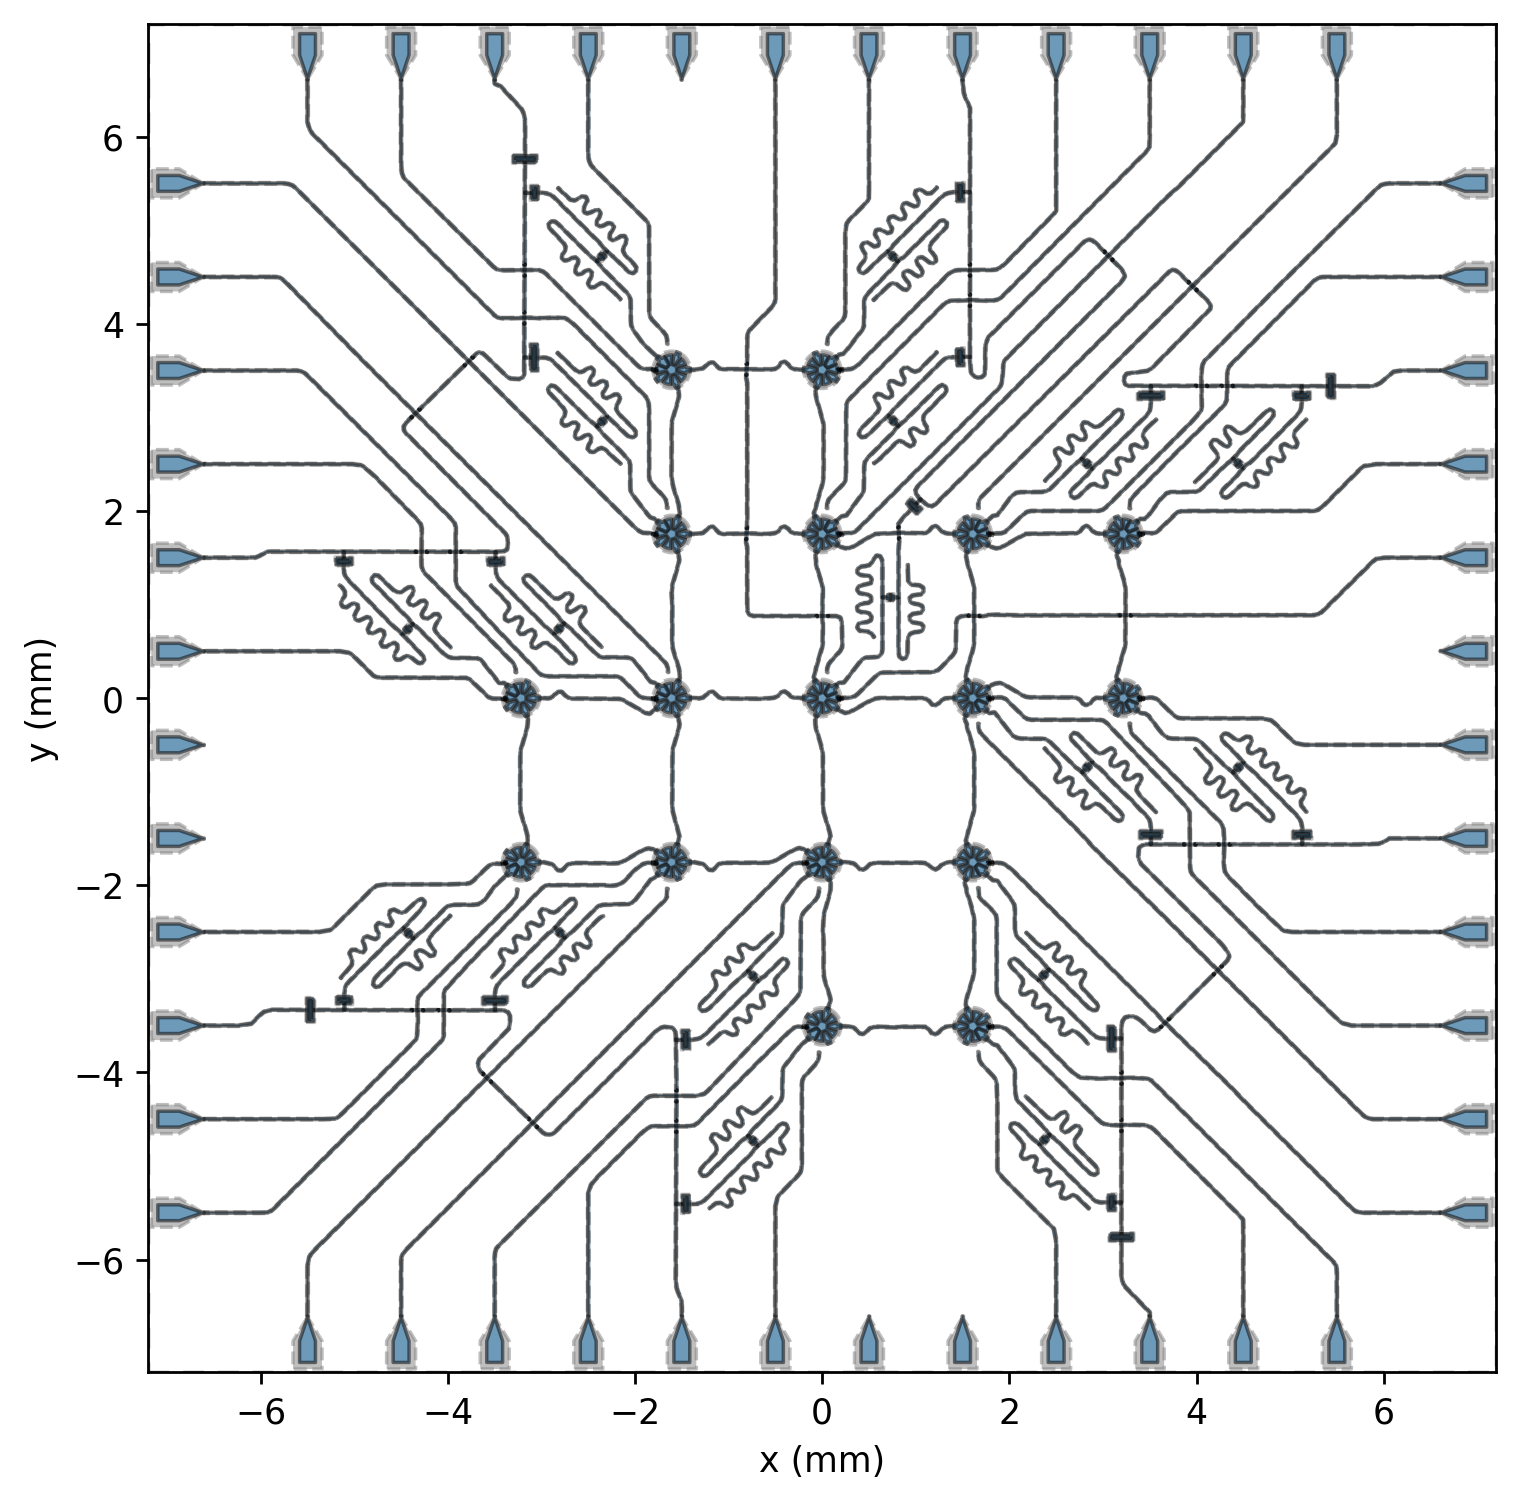

In [28]:
# --- Four Multiplexed Feedline Groups ---
chip.stage_feedlines(design)
print("Four feedline groups with native in-line input capacitors.")

fig = qm.view(design)
fig.set_size_inches(7, 7)
ax = fig.axes[0]
ax.set_xlim(-chip_x / 2, chip_x / 2)
ax.set_ylim(-chip_y / 2, chip_y / 2)
ax.set_aspect("equal")
ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
display(fig)
plt.close(fig)

## The finished chip 🎉

Every rule passes. The one warning is the ground islands from step 3.

In [29]:
# --- Signal Crossover Process Masks ---
crossings = []
for old in list(design.components.values()):
    if not isinstance(old, Airbridge):
        continue
    name = "XO_" + old.name
    cx, cy = float(old.p.pos_x), float(old.p.pos_y)
    angle = float(old.p.orientation)
    length = float(old.p.crossover_length)
    feet_center = length / 2 + 0.0055
    peers = []
    for pin_name in ("a", "b"):
        net_id = old.pins[pin_name].net_id
        match = design.net_info[
            (design.net_info.net_id == net_id)
            & (design.net_info.component_id != old.id)
        ]
        for _, peer in match.iterrows():
            peers.append(
                (
                    pin_name,
                    design._components[int(peer.component_id)].name,
                    peer.pin_name,
                )
            )
    pin_points = {p: old.pins[p].points.copy() for p in ("a", "b")}
    design.delete_component(old.name)
    crossing = QComponent(
        design,
        name,
        options=Dict(
            pos_x=f"{cx}mm", pos_y=f"{cy}mm", orientation=str(angle), layer="1"
        ),
        make=False,
    )
    feet = draw.union(
        draw.rectangle(0.011, 0.011, -feet_center, 0),
        draw.rectangle(0.011, 0.011, feet_center, 0),
    )
    clearance = draw.union(
        draw.rectangle(0.022, 0.022, -feet_center, 0),
        draw.rectangle(0.022, 0.022, feet_center, 0),
    )
    span = draw.rectangle(2 * (feet_center + 0.005), 0.0085)
    scaffold = draw.rectangle(length + 0.001, 0.0195)
    contacts = draw.union(
        draw.rectangle(0.006, 0.005, -feet_center, 0),
        draw.rectangle(0.006, 0.005, feet_center, 0),
    )
    objects = draw.translate(
        draw.rotate([feet, clearance, span, scaffold, contacts], angle, origin=(0, 0)),
        cx,
        cy,
    )
    feet, clearance, span, scaffold, contacts = objects
    crossing.add_qgeometry("poly", {"base_landings": feet}, layer=1)
    crossing.add_qgeometry(
        "poly", {"landing_clearance": clearance}, layer=1, subtract=True
    )
    crossing.add_qgeometry("poly", {"reflow_scaffold": scaffold}, layer=2)
    crossing.add_qgeometry("poly", {"AlTiAl_overpass": span}, layer=3)
    crossing.add_qgeometry("poly", {"contacts": contacts}, layer=4)
    for p in ("a", "b"):
        middle = np.asarray(pin_points[p]).mean(axis=0)
        peer_name, peer_pin = next((n, pn) for pin, n, pn in peers if pin == p)
        route = design.components[peer_name]
        trace = route.qgeometry_table("path")
        coords = np.asarray(trace[~trace["subtract"]].iloc[0].geometry.coords)
        if np.linalg.norm(coords[-1] - middle) < np.linalg.norm(coords[0] - middle):
            coords = coords[::-1]
        normal = coords[1] - coords[0]
        normal /= np.linalg.norm(normal)
        crossing.add_pin(
            p,
            np.array([middle - 0.01 * normal, middle]),
            width=0.011,
            input_as_norm=True,
        )
    for p, peer_name, peer_pin in peers:
        design.connect_pins(crossing.id, p, design.components[peer_name].id, peer_pin)
    crossings.append(crossing)
print(
    f"{len(crossings)} signal crossings with isolated Nb landings and Al-Ti-Al spans."
)

30 signal crossings with isolated Nb landings and Al-Ti-Al spans.


In [30]:
# --- Ground Straps Along the Filleted CPWs ---
ground_sheet = GroundContinuityRule(chip="main", layer=1)._ground_sheet(
    design, chip="main"
)
ground_regions = [
    p for p in getattr(ground_sheet, "geoms", [ground_sheet]) if p.area > 1e-4
]
ground_graph = nx.Graph()
ground_graph.add_nodes_from(range(len(ground_regions)))
bridge_spans = [
    c.qgeometry_table("poly").query("subtract == False").geometry.union_all()
    for c in crossings
]
ground_straps = []
strap_pitch = GROUND_STRAP_PITCH
for route in list(design.components.values()):
    if not isinstance(route, chip.PolylineCPW):
        continue
    paths = route.qgeometry_table("path")
    points = np.asarray(paths[~paths["subtract"]].iloc[0].geometry.coords)
    steps = np.diff(points, axis=0)
    turns = steps[:-1, 0] * steps[1:, 1] - steps[:-1, 1] * steps[1:, 0]
    points = points[np.r_[True, np.abs(turns) > 1e-12, True]]
    proxy = SimpleNamespace(
        name=route.name, options=route.options, get_points=points.copy
    )
    candidates = route_airbridges(
        design,
        proxy,
        pitch=strap_pitch,
        min_spacing="100um",
        crossover_length=0.050,
        name="GS_" + route.name,
    )
    for candidate in candidates:
        cx, cy = float(candidate.p.pos_x), float(candidate.p.pos_y)
        angle = float(candidate.p.orientation)
        feet_center = 0.0305
        feet = [draw.rectangle(0.011, 0.011, side * feet_center, 0) for side in (-1, 1)]
        span = draw.rectangle(0.071, 0.0085)
        scaffold = draw.rectangle(0.051, 0.0195)
        contacts = draw.union(
            *[draw.rectangle(0.006, 0.005, side * feet_center, 0) for side in (-1, 1)]
        )
        feet = draw.translate(draw.rotate(feet, angle, origin=(0, 0)), cx, cy)
        span, scaffold, contacts = draw.translate(
            draw.rotate([span, scaffold, contacts], angle, origin=(0, 0)), cx, cy
        )
        name = candidate.name
        design.delete_component(name)
        regions = []
        for foot in feet:
            matches = [
                i
                for i, region in enumerate(ground_regions)
                if region.covers(foot.buffer(0.001))
            ]
            if matches:
                regions.append(matches[0])
        if len(regions) != 2:
            continue
        envelope = draw.union(span, scaffold, *feet)
        if any(envelope.distance(other) < 0.003 for other in bridge_spans):
            continue
        strap = QComponent(
            design,
            name,
            options=Dict(
                pos_x=f"{cx}mm",
                pos_y=f"{cy}mm",
                orientation=str(angle),
                layer="1",
            ),
            make=False,
        )
        strap.add_qgeometry("poly", {"ground_landings": draw.union(*feet)}, layer=1)
        strap.add_qgeometry("poly", {"reflow_scaffold": scaffold}, layer=2)
        strap.add_qgeometry("poly", {"AlTiAl_ground_strap": span}, layer=3)
        strap.add_qgeometry("poly", {"contacts": contacts}, layer=4)
        ground_straps.append(strap)
        bridge_spans.append(envelope)
        ground_graph.add_edge(*regions)
assert nx.is_connected(ground_graph), list(nx.connected_components(ground_graph))
print(
    f"{len(ground_straps)} ground straps connect all {len(ground_regions)} Nb ground regions."
)

737 ground straps connect all 9 Nb ground regions.


In [31]:
# --- Native Geometry and Routing Checks ---
assert len(crossings) == 30
assert nx.is_connected(ground_graph)
for table_name in ("poly", "path", "junction"):
    table = design.qgeometry.tables[table_name]
    assert table.geometry.is_valid.all(), table_name
    assert not table.geometry.is_empty.any(), table_name
    bounds = table.geometry.total_bounds
    assert bounds[0] >= -chip_x / 2 and bounds[2] <= chip_x / 2, table_name
    assert bounds[1] >= -chip_y / 2 and bounds[3] <= chip_y / 2, table_name

# The native ground rule checks layer 1 alone; the bridge graph checks its straps.
waivers = [
    Waiver(
        rule="ground-continuity",
        reason=f"All {len(ground_regions)} base-metal regions connect through verified layer-3 ground straps and layer-4 contacts.",
    )
]
drc = validate(design, rules=RULES, waivers=waivers)
print(drc.report())
drc.raise_if_errors()

# --- Process Contact Checks ---
for crossing in crossings + ground_straps:
    metal = crossing.qgeometry_table("poly")
    base = metal[(metal.layer == 1) & ~metal["subtract"]].geometry.union_all()
    upper = metal[metal.layer == 3].geometry.union_all()
    contacts = metal[metal.layer == 4].geometry.union_all()
    assert base.buffer(1e-9).covers(contacts), crossing.name
    assert upper.buffer(1e-9).covers(contacts), crossing.name
for name in chip.QUBITS:
    squid = design.components[f"SQUID_{name}"]
    metal = squid.qgeometry_table("poly")
    lower = metal[metal.layer == 5].geometry.union_all()
    upper = metal[metal.layer == 6].geometry.union_all()
    overlaps = metal[metal.layer == 7].geometry.union_all()
    assert np.isclose(lower.intersection(upper).area, 1.2e-7, rtol=0, atol=1e-12), name
    assert lower.intersection(upper).symmetric_difference(overlaps).area < 1e-12, name
for pad in [c for c in design.components.values() if c.name.startswith("LP_")]:
    metal = pad.qgeometry_table("poly")
    xmin, ymin, xmax, ymax = metal[~metal["subtract"]].geometry.union_all().bounds
    distance = min(
        xmin + chip_x / 2, ymin + chip_y / 2, chip_x / 2 - xmax, chip_y / 2 - ymax
    )
    assert np.isclose(distance, 0.100, atol=1e-6), pad.name
kinds = Counter(
    "qubit" if name in chip.QUBITS else name.split("_")[0] for name in design.components
)
display(pd.DataFrame(sorted(kinds.items()), columns=["Component group", "Count"]))
print(
    f"Ground connectivity: {len(ground_regions)} regions, one connected network, {len(ground_straps)} straps."
)

Design rules passed (12 rules ran, no findings).
1 waived:
  [warning] ground-continuity: ground plane on layer 1 is split into 9 disconnected regions (mm^2: 170.430, 2.616, 2.604, 2.595, ...); confirm airbridges or vias tie them together -- this check sees only same-layer metal  @ (1.1882, 0.8390)
      waived: All 9 base-metal regions connect through verified layer-3 ground straps and layer-4 contacts.


,Component group,Count
0,CPL,24
1,DRIVE,20
2,DRIVEOPEN,17
3,FEED,28
4,FEEDCAP,4
5,FEEDIN,4
6,FLUX,19
7,FLUXSHORT,17
8,GS,737
9,LP,48


Ground connectivity: 9 regions, one connected network, 737 straps.


### Inspect every qubit

One zoomed panel per qubit: the island, its couplers, and where the flux and drive lines stop. Mistakes that vanish in a whole-chip view — a line ending on the wrong side, a gap that differs from qubit to qubit — stand out when all seventeen sit side by side.

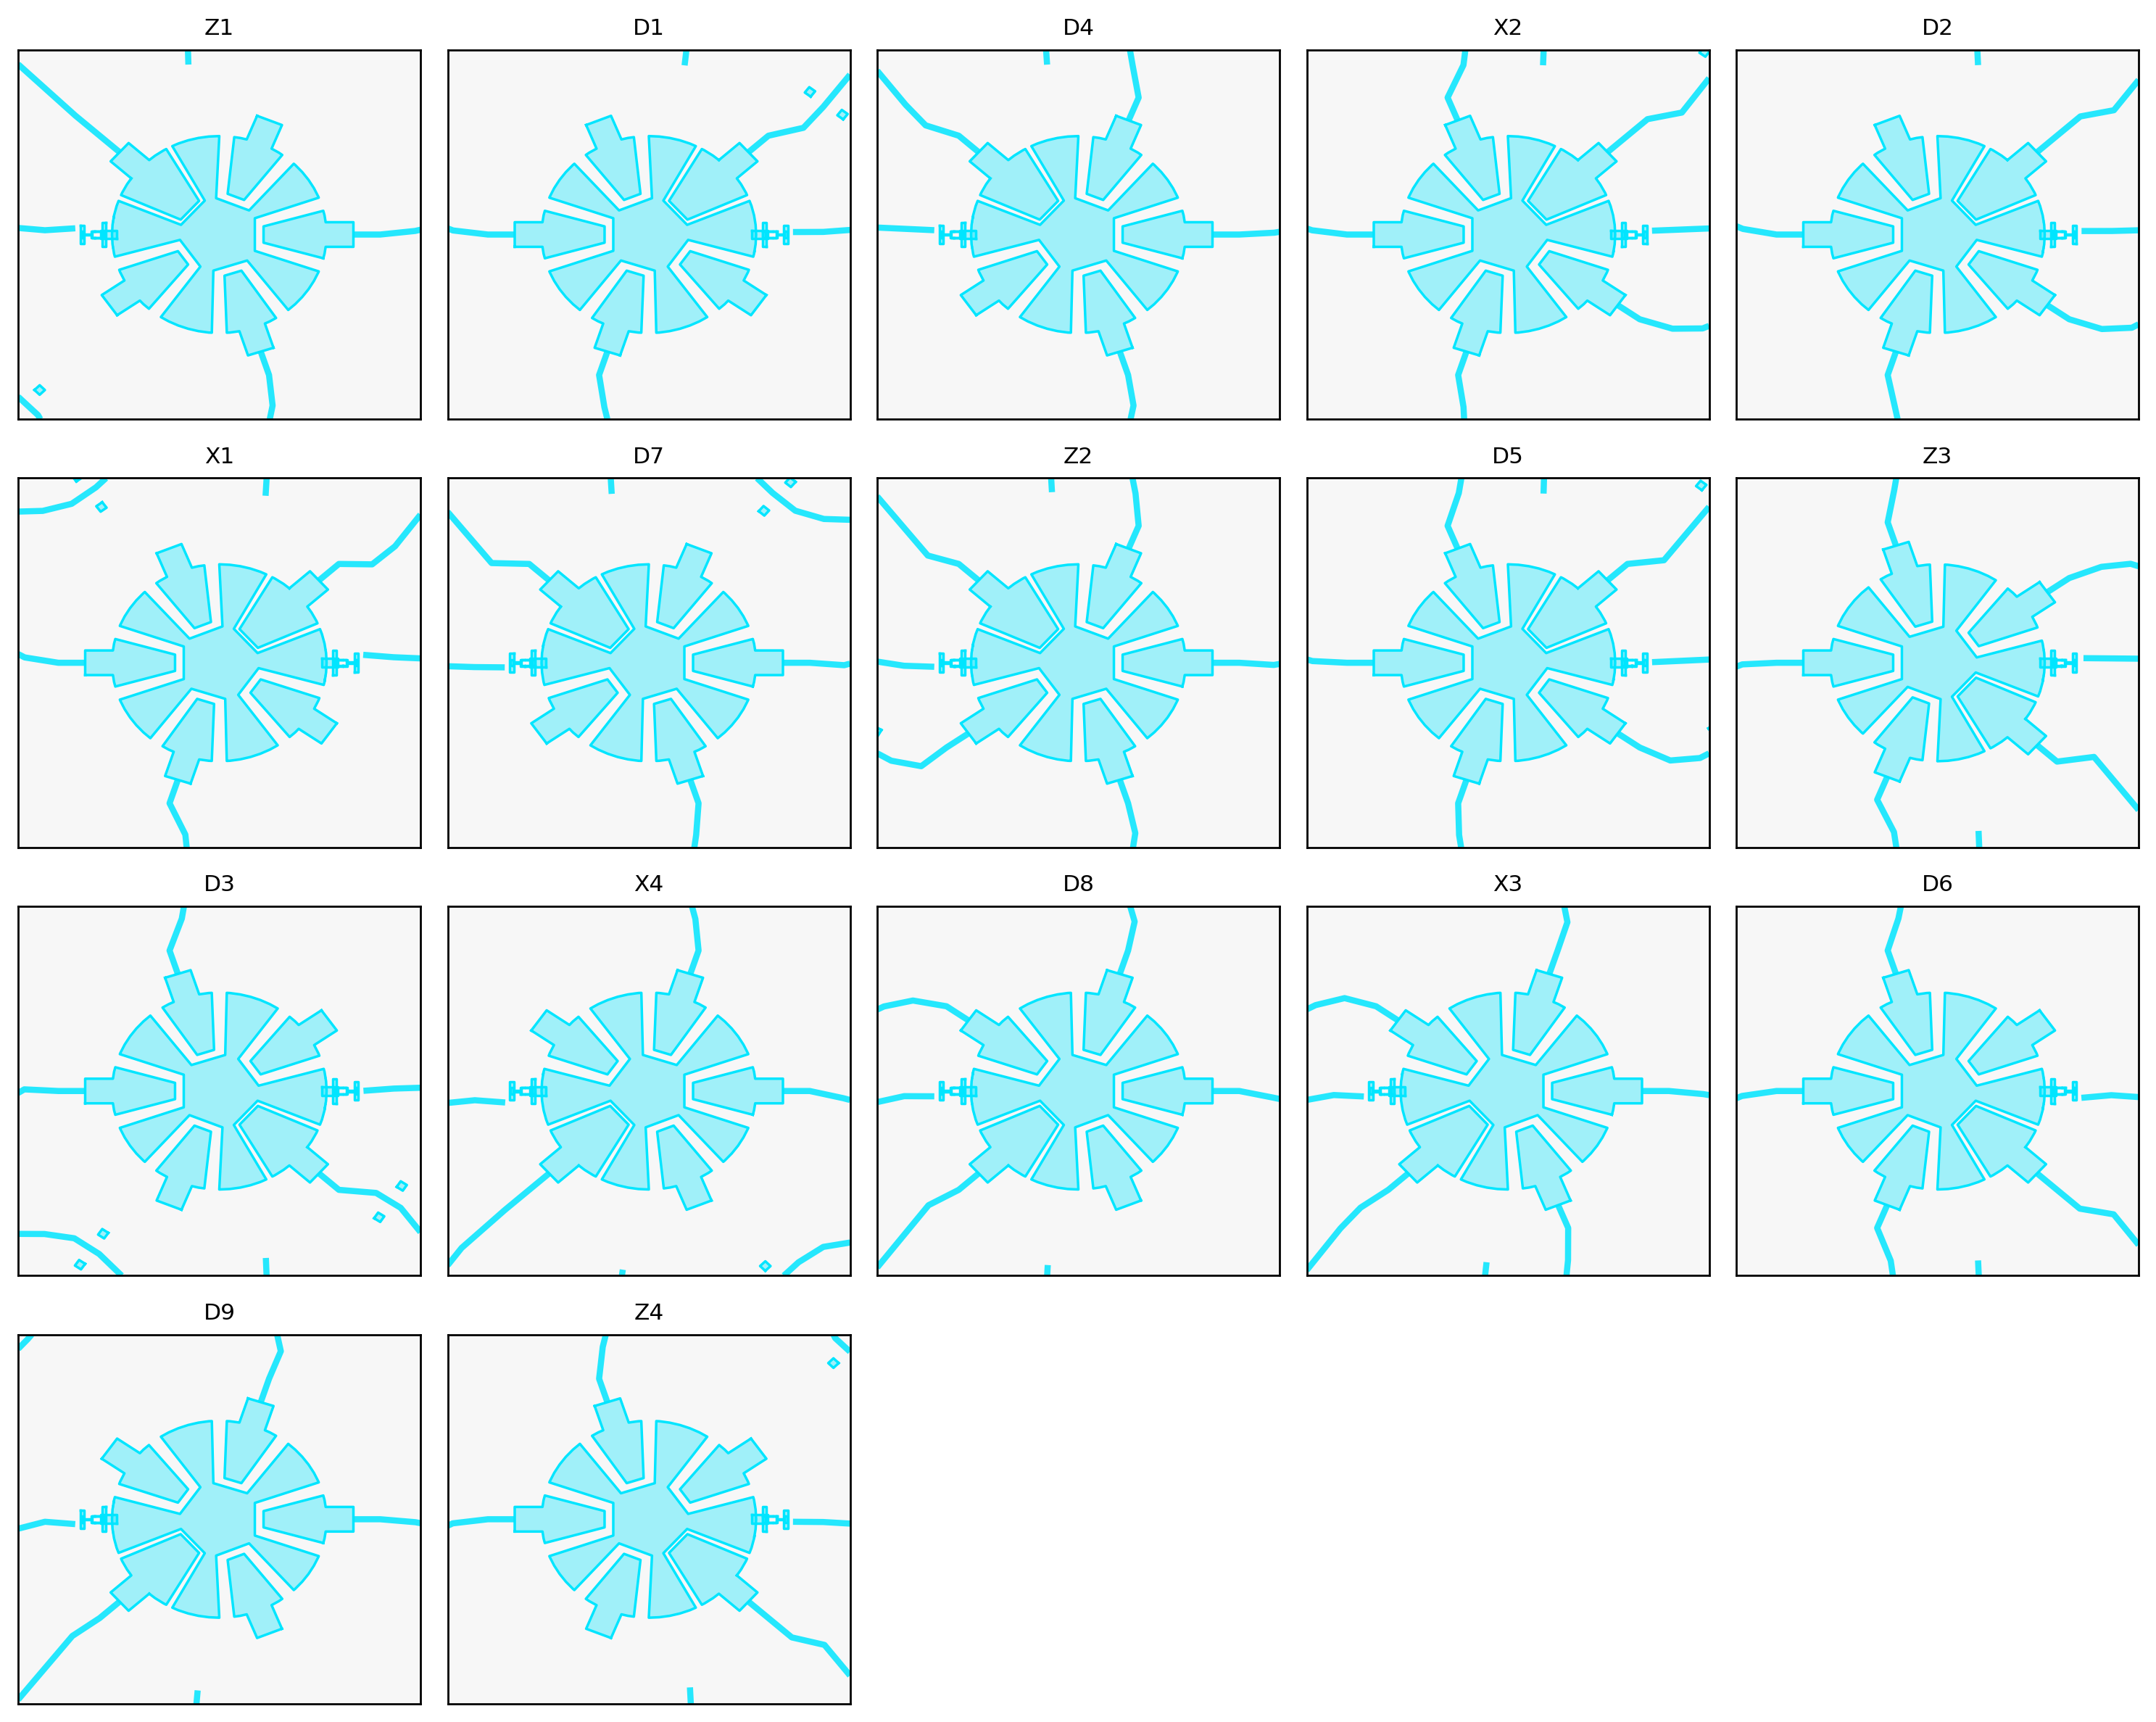

In [32]:
# --- Inspect All Qubit Sites ---
fig = inspect_sites(
    design,
    {q: list(p) for q, p in chip.QUBIT_POS.items()},
    radius=0.30,
    cols=5,
    layers=[1, 5, 6, 7, 8],
    figsize_per=2.4,
)
plt.show()

### Export to GDS

The mask file, ready for a layout viewer such as KLayout.

/usr/local/lib/python3.13/dist-packages/qiskit_metal/renderers/renderer_gds/gds_boolean.py:108: RuntimeWarning: Error in boolean operation.
  fast = gdstk.boolean(


GDSII: Wallraff_17Q.gds (3,095,538 bytes); layers 1–8; 34 junction overlaps.


/content/Wallraff_17Q.gds

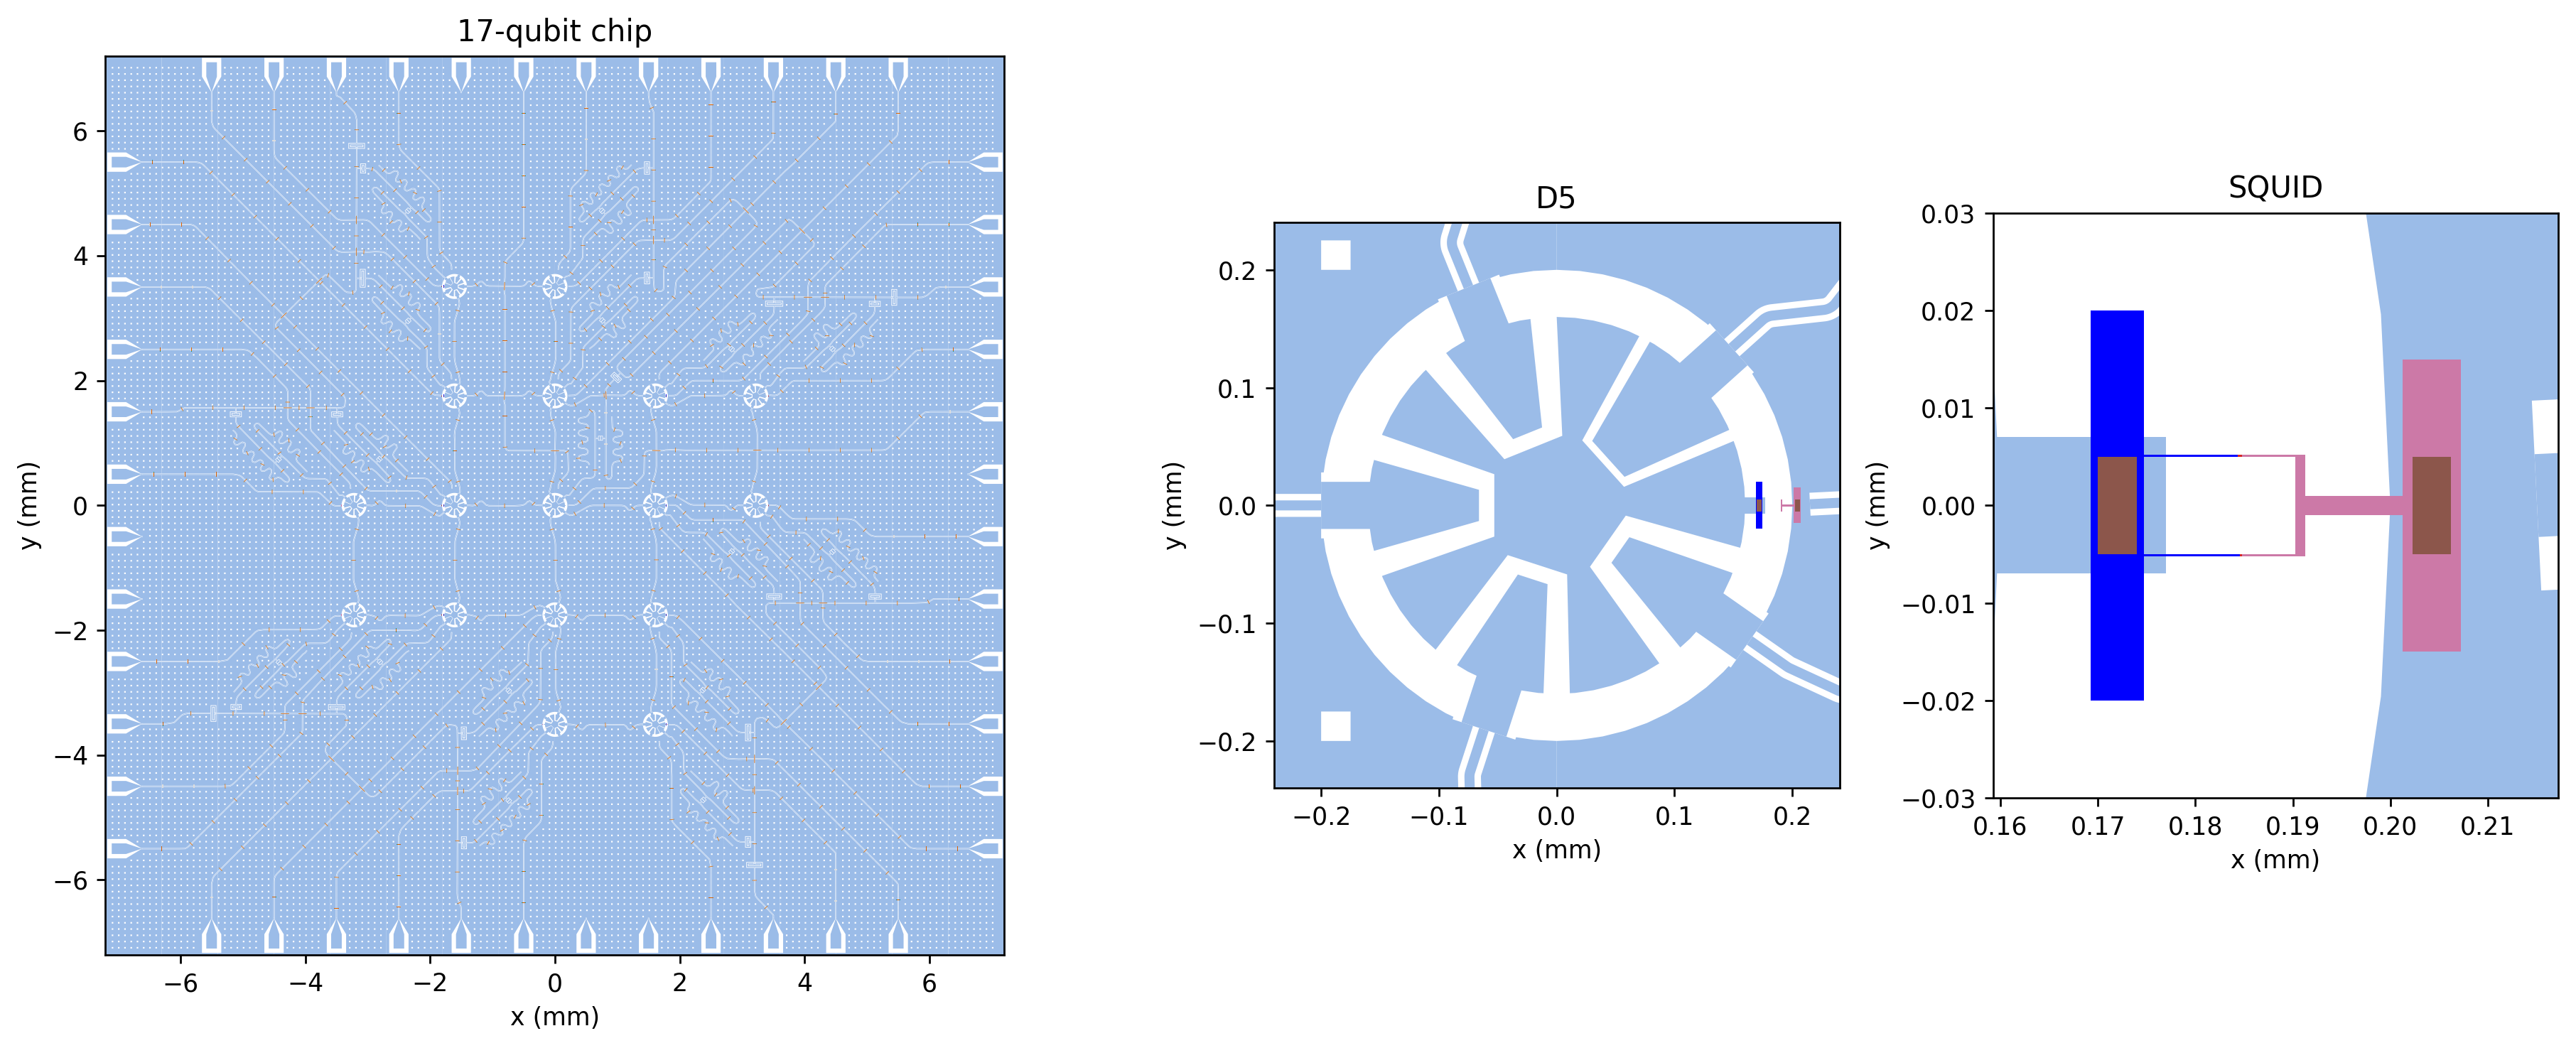

In [33]:
# --- Native Cheesing and GDS Export ---

out = Path.cwd() / OUTPUT_FILENAME
gds = QGDSRenderer(design, initiate=False)
gds.options.precision = "1e-9"
gds.options.tolerance = "1e-6"
gds.options.fabricate = "True"
gds.options.short_segments_to_not_fillet = "False"
gds.options.max_points = "8190"
gds.options.path_filename = ""
gds.options.cheese = QGDSRenderer.default_options.cheese.copy()
gds.options.no_cheese = QGDSRenderer.default_options.no_cheese.copy()
gds.options.cheese.edge_nocheese = "112.5um"
gds.options.no_cheese.buffer = CHEESE_KEEPOUT
gds.options.cheese.view_in_file = Dict(
    main={layer: layer == 1 for layer in range(1, 9)}
)
gds.options.no_cheese.view_in_file = Dict(main={layer: False for layer in range(1, 9)})

# Physical junction electrodes are already present on layers 5, 6, and 7.
junction_table = design.qgeometry.tables["junction"].copy(deep=True)
design.qgeometry.tables["junction"] = junction_table.iloc[:0].copy()
previous_log_level = qm.logger.level
qm.logger.setLevel(logging.ERROR)
try:
    with warnings.catch_warnings():
        warnings.filterwarnings(
            "ignore",
            category=FutureWarning,
            message="The behavior of DataFrame concatenation.*",
        )
        export_status = gds.export_to_gds(str(out))
finally:
    design.qgeometry.tables["junction"] = junction_table
    qm.logger.setLevel(previous_log_level)
assert export_status and out.is_file() and out.stat().st_size > 0

# Remove references to temporary cells omitted by the native fabrication export.
cell_names = {cell.name for cell in gds.lib.cells}
for cell in gds.lib.cells:
    for reference in list(cell.references):
        if reference.cell_name not in cell_names:
            cell.remove(reference)
gds.lib.write_gds(str(out), max_points=8190)

# --- GDS Readback Checks ---
verified_gds = gdstk.read_gds(str(out))
top_cells = verified_gds.top_level()
assert len(top_cells) == 1
exported_polygons = top_cells[0].get_polygons()
assert {polygon.layer for polygon in exported_polygons} == set(range(1, 9))
assert np.isclose(verified_gds.precision, 1e-9, rtol=0, atol=1e-15)
assert np.isclose(verified_gds.unit, 1e-3, rtol=0, atol=1e-12)
assert len([p for p in exported_polygons if p.layer == 7]) == 34
for layer in range(2, 9):
    assert sum(p.area() for p in exported_polygons if p.layer == layer) < 1
overlap_areas = sorted(p.area() * 1e6 for p in exported_polygons if p.layer == 7)
assert np.allclose(overlap_areas, [0.04] * 17 + [0.08] * 17, rtol=0, atol=1e-6)
print(
    f"GDSII: {out.name} ({out.stat().st_size:,} bytes); layers 1–8; 34 junction overlaps."
)
display(FileLink(str(out)))

# Every bridge contact must meet both its base metal and its elevated span.
contact_polygons = [p for p in exported_polygons if p.layer == 4]
for layer in (1, 3):
    missing_contact = gdstk.boolean(
        contact_polygons,
        [p for p in exported_polygons if p.layer == layer],
        "not",
        precision=1e-6,
    )
    assert sum(p.area() for p in missing_contact) < 1e-10, layer


# --- In-Memory GDS Preview ---
colors = {
    1: "#9bbce8",
    2: "#dddddd",
    3: "#d65f00",
    4: "#009e73",
    5: "#0000ff",
    6: "#cc79a7",
    7: "#d62728",
    8: "#8c564b",
}
fig, axes = plt.subplots(
    1, 3, figsize=(15, 6), dpi=250, gridspec_kw={"width_ratios": [2, 1, 1]}
)
squid = design.components["SQUID_D5"]
q = design.components["D5"]
sxmin, symin, sxmax, symax = squid.qgeometry_bounds()
center = np.array([float(q.p.pos_x), float(q.p.pos_y)])
views = [
    (-chip_x / 2, chip_x / 2, -chip_y / 2, chip_y / 2, "17-qubit chip"),
    (center[0] - 0.24, center[0] + 0.24, center[1] - 0.24, center[1] + 0.24, "D5"),
    (sxmin - 0.010, sxmax + 0.010, symin - 0.010, symax + 0.010, "SQUID"),
]
for ax, (xmin, xmax, ymin, ymax, title) in zip(axes, views):
    for layer, color in colors.items():
        ax.add_collection(
            PolyCollection(
                [p.points for p in exported_polygons if p.layer == layer],
                facecolor=color,
                edgecolor="none",
                rasterized=True,
            )
        )
    ax.set(xlim=(xmin, xmax), ylim=(ymin, ymax), aspect="equal")
    ax.set_xlabel("x (mm)", fontfamily="DejaVu Sans", weight="normal")
    ax.set_ylabel("y (mm)", fontfamily="DejaVu Sans", weight="normal")
    ax.set_title(title, fontfamily="DejaVu Sans", weight="normal")
    ax.ticklabel_format(useOffset=False)
fig.tight_layout()
plt.show()

## 🧪 Play with it

The design is live: change an option, rebuild, and check again.

**Tune a Purcell coupler.** The filter–feedline coupling of qubit `D5` is set by the length of its `CapFingerInFrame`. Make it longer and look at it before and after.

In [34]:
# --- Optional Capacitor Experiment ---
if False:
    cap = design.components["PUCAP_D5"]
    cap.options.frame_length = "220um"
    cap.rebuild()
    print(validate(design, rules=RULES, waivers=waivers).report())

**Break it on purpose.** Delete the open termination at the end of `D5`'s drive line. Nothing looks different at chip scale, but the line now ends against the ground plane — a short on the wafer. The check catches it and says where.

In [35]:
# --- Optional Routing-Rule Experiment ---
if False:
    design.delete_component("DRIVEOPEN_D5")
    print(validate(design, rules=RULES, waivers=waivers).report())

**More to try**

- Rebuild the whole chip with a different coplanar cross-section (it is 8.5 µm center conductor, 5.5 µm gap): `chip.CPW.update(width="10um", gap="6um")`, then `design = chip.build()`, `gui.set_design(design)` and `check(design)`.
- In the desktop GUI, click through the components by name and edit an option in the component panel; rerun `check(design)` to see what changed.
- Cut out one unit cell — two qubits and their coupler — and mesh it for a capacitance simulation.
- Ask an AI agent with the [`chip-design`](https://github.com/qiskit-community/qiskit-metal/blob/main/.claude/skills/chip-design/SKILL.md) skill to design a new chip from a specification of your own — say, a smaller surface-code patch with your frequency plan — and check it the same way.

## Known issues — this is a mockup

- **Crossovers.** Where one line crosses another, the device uses integrated crossovers. Here each crossing is an `Airbridge` over a cut in the line: electrically a crossing, but not the same structure.
- **Junctions.** `StarQubit` draws a single junction where the device has a SQUID. It sits on the island arm facing the flux line, as on the device; the flux line ends in a short just outside the pocket beside it.
- **Pad angles** follow a regular 72° pattern; the device's are within 6° of it.
- **Dimensions finer than the images** (about 7.5 µm per pixel) are chosen, not measured: the coplanar center conductor and gap (8.5 and 5.5 µm, from the measured 14 µm total at 50 Ω on silicon) and the capacitor gaps (10 µm, consistent with every measured spacing).
- **Airbridges** are placed only where one line crosses another; the ground-strapping bridges along the lines are not.

## Acknowledgements

The device design is by the Quantum Device Lab, ETH Zurich (A. Wallraff). We thank Andreas Wallraff and the team for sharing it openly through the [lecture slides](https://polybox.ethz.ch/index.php/s/CnsHoKWW6xQKZAA) and talks ([1](https://www.youtube.com/watch?v=floIDDd6ZXA), [2](https://www.youtube.com/watch?v=CgNz4wsD0oI), [3](https://www.youtube.com/watch?v=0r1YPMcmuFU), the last at the Quantum Device Workshop), which made this reconstruction possible. The Quantum Metal layout was rebuilt by AI agents working with Quantum Metal, reviewed stage by stage.

## References

**The device and its experiments**

1. S. Krinner, N. Lacroix, A. Remm *et al.*, "Realizing repeated quantum error correction in a distance-three surface code," *Nature* **605**, 669–674 (2022). [doi:10.1038/s41586-022-04566-8](https://doi.org/10.1038/s41586-022-04566-8)
2. I. Besedin, M. Kerschbaum, J. Knoll *et al.*, "Lattice surgery realized on two distance-three repetition codes with superconducting qubits," *Nature Physics* **22**, 189–194 (2026). [doi:10.1038/s41567-025-03090-6](https://doi.org/10.1038/s41567-025-03090-6) · [arXiv:2501.04612](https://arxiv.org/abs/2501.04612)
3. C. K. Andersen, A. Remm, S. Lazar *et al.*, "Repeated quantum error detection in a surface code," *Nature Physics* **16**, 875–880 (2020). [doi:10.1038/s41567-020-0920-y](https://doi.org/10.1038/s41567-020-0920-y)

**Readout and Purcell filters**

4. J. Heinsoo, C. K. Andersen, A. Remm *et al.*, "Rapid high-fidelity multiplexed readout of superconducting qubits," *Phys. Rev. Applied* **10**, 034040 (2018). [doi:10.1103/PhysRevApplied.10.034040](https://doi.org/10.1103/PhysRevApplied.10.034040)
5. T. Walter, P. Kurpiers, S. Gasparinetti *et al.*, "Rapid high-fidelity single-shot dispersive readout of superconducting qubits," *Phys. Rev. Applied* **7**, 054020 (2017). [doi:10.1103/PhysRevApplied.7.054020](https://doi.org/10.1103/PhysRevApplied.7.054020)

**Background**

6. A. G. Fowler, M. Mariantoni, J. M. Martinis, A. N. Cleland, "Surface codes: Towards practical large-scale quantum computation," *Phys. Rev. A* **86**, 032324 (2012). [doi:10.1103/PhysRevA.86.032324](https://doi.org/10.1103/PhysRevA.86.032324)
7. J. Koch, T. M. Yu, J. Gambetta *et al.*, "Charge-insensitive qubit design derived from the Cooper pair box," *Phys. Rev. A* **76**, 042319 (2007). [doi:10.1103/PhysRevA.76.042319](https://doi.org/10.1103/PhysRevA.76.042319)
8. A. Blais, A. L. Grimsmo, S. M. Girvin, A. Wallraff, "Circuit quantum electrodynamics," *Rev. Mod. Phys.* **93**, 025005 (2021). [doi:10.1103/RevModPhys.93.025005](https://doi.org/10.1103/RevModPhys.93.025005)
9. S. Krinner, S. Storz, P. Kurpiers *et al.*, "Engineering cryogenic setups for 100-qubit scale superconducting circuit systems," *EPJ Quantum Technology* **6**, 2 (2019). [doi:10.1140/epjqt/s40507-019-0072-0](https://doi.org/10.1140/epjqt/s40507-019-0072-0)

**Sources for the geometry**

10. A. Wallraff, lecture slides and talks, Quantum Device Lab, ETH Zurich: [slides](https://polybox.ethz.ch/index.php/s/CnsHoKWW6xQKZAA); talks [1](https://www.youtube.com/watch?v=floIDDd6ZXA), [2](https://www.youtube.com/watch?v=CgNz4wsD0oI), [3](https://www.youtube.com/watch?v=0r1YPMcmuFU) (Quantum Device Workshop).